In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve,
    mean_absolute_error, mean_squared_error, r2_score,
)
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

## Load the data

Uses the committed `titanic.csv` directly. Nothing is downloaded from the network.

In [2]:
df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.lower()
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Task 7: Stratified train/test split (done BEFORE any preprocessing)

Target: `survived`. Features: `pclass, sex, age, sibsp, parch, fare, embarked`.
`adult_male`, `alone`, `who`, `alive`, `class`, `embark_town` and `deck` are left out because they are
duplicates or direct encodings of other columns (`alive` is literally the target), which would cause leakage or redundancy.

In [3]:
FEATURES = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
TARGET = "survived"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Class balance (whole dataset):")
print(y.value_counts().to_frame("count").assign(share=y.value_counts(normalize=True).round(3)))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("\nTrain shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Survival rate  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Class balance (whole dataset):
          count  share
survived              
0           549  0.616
1           342  0.384

Train shape: (712, 7) | Test shape: (179, 7)
Survival rate  train: 0.383 | test: 0.385


**Why stratification matters here (edit with your own Task 1 numbers):**
Only about [38]% of passengers survived, so the classes are imbalanced. A plain random split could, by chance,
put noticeably more or fewer survivors in the test set, which makes the metrics unreliable and not comparable
between models. Stratifying on `survived` keeps the survival rate almost identical in train and test
(shown above), so every model is trained and judged on the same class proportions.

## Task 8: Preprocessing (fit on TRAIN only, transform-only on test)

My choices:
- **Missing values:** `age` and numeric columns use the **median** (robust to outliers); `embarked` uses the **most frequent** value.
- **Encoding:** `sex` and `embarked` use **one-hot encoding**.
- **Scaling:** numeric columns use **StandardScaler**.

Everything lives inside a `ColumnTransformer` wrapped in a `Pipeline`, so `fit` only ever sees training data
and `predict` on the test set only calls `transform`. Nothing can leak by accident.

In [4]:
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

def build_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ])

print("Missing values in TRAIN features (handled inside the pipeline):")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Missing values in TRAIN features (handled inside the pipeline):
age         137
embarked      2
dtype: int64


## Task 9: Train three classifiers on the identical split

In [5]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

fitted = {}
for name, clf in classifiers.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)          # preprocessing is fit on the training split only
    fitted[name] = pipe
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


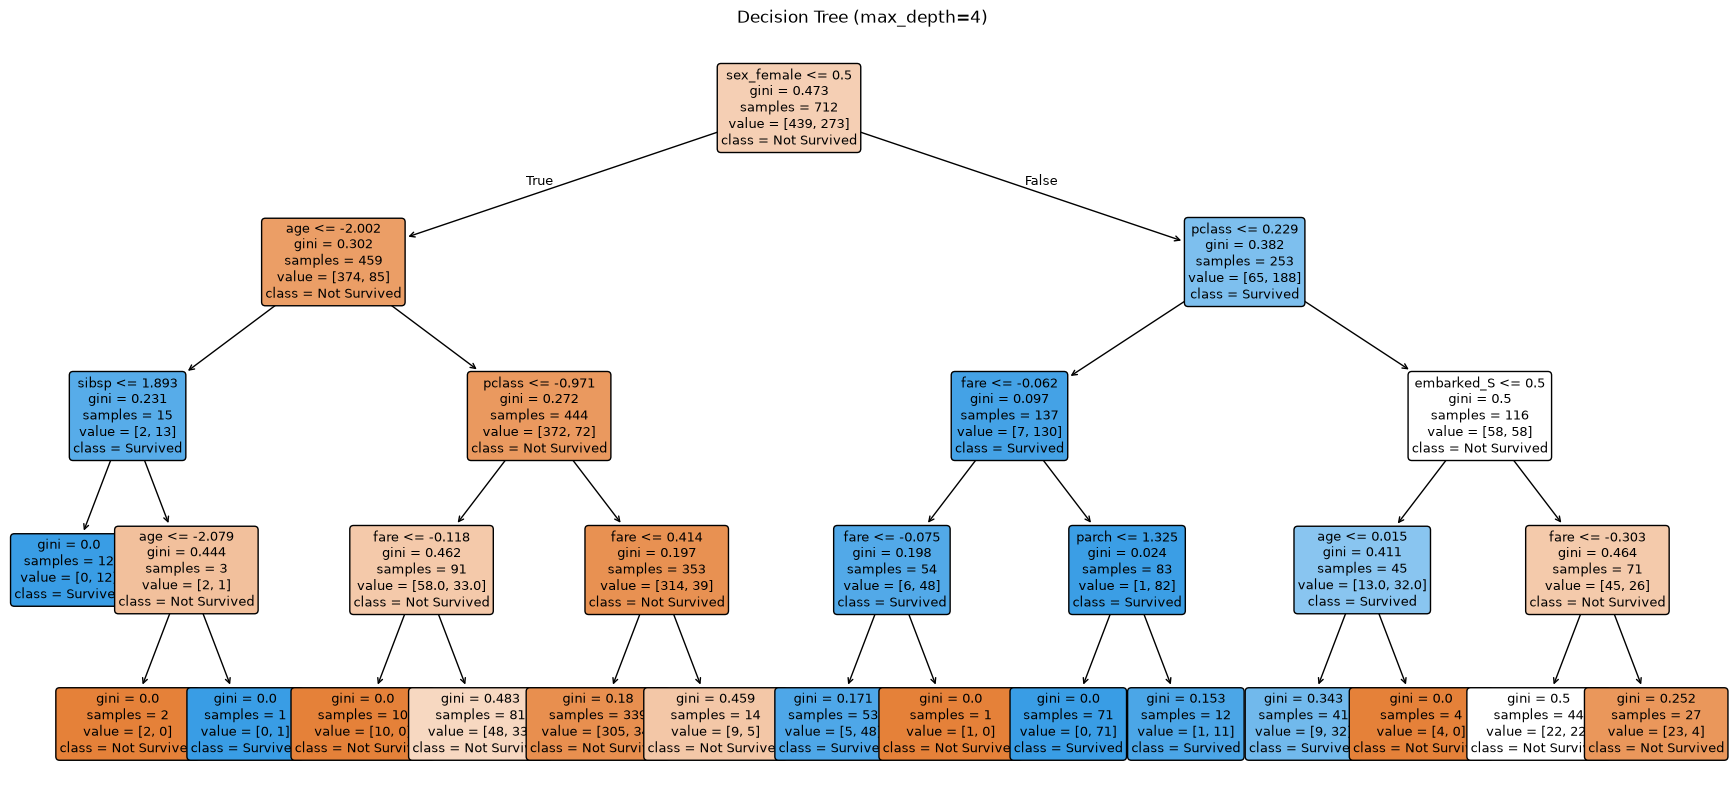

In [6]:
# Decision Tree visualisation with labelled features and classes
dt_pipe = fitted["Decision Tree"]
raw_names = dt_pipe.named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in raw_names]

plt.figure(figsize=(22, 10))
plot_tree(
    dt_pipe.named_steps["clf"],
    feature_names=feature_names,
    class_names=["Not Survived", "Survived"],
    filled=True, rounded=True, fontsize=9,
)
plt.title("Decision Tree (max_depth=4)")
plt.show()

## Task 10: Evaluate all three models

Confusion matrix, accuracy, precision, recall, F1, ROC curve with AUC, all on the held-out test set.

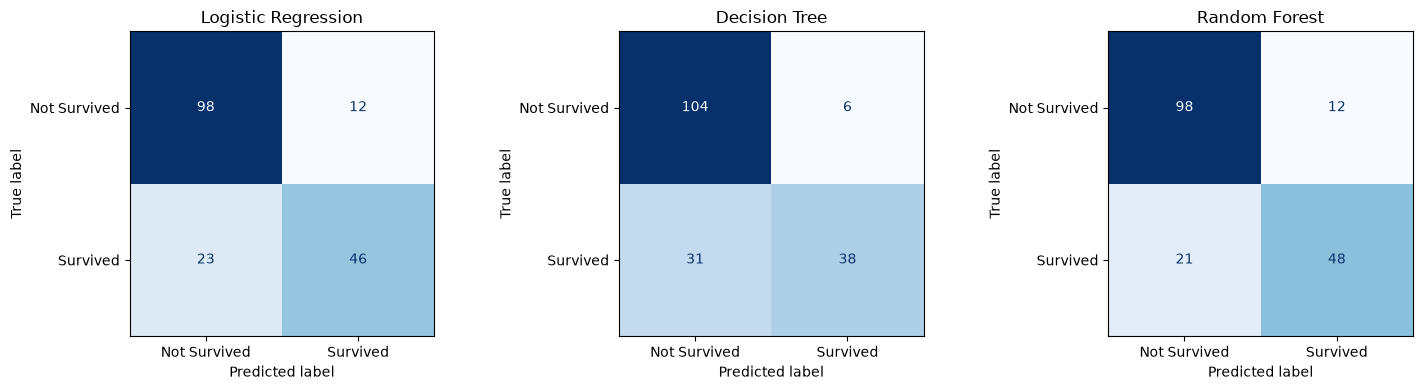

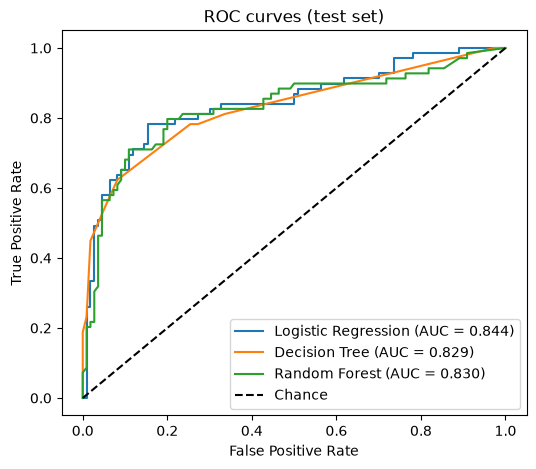

Side-by-side comparison (test set):


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.804,0.793,0.667,0.724,0.844
Decision Tree,0.793,0.864,0.551,0.673,0.829
Random Forest,0.816,0.800,0.696,0.744,0.830


In [7]:
def evaluate_classifier(pipe, X_te, y_te):
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]
    return {
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "ROC-AUC": roc_auc_score(y_te, proba),
    }

clf_results = pd.DataFrame({name: evaluate_classifier(p, X_test, y_test) for name, p in fitted.items()}).T

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test, display_labels=["Not Survived", "Survived"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ROC curves
plt.figure(figsize=(6, 5))
for name, pipe in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {clf_results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves (test set)"); plt.legend(); plt.show()

print("Side-by-side comparison (test set):")
clf_results.round(3)

## Task 11: Imbalance handling comparison

Three variants of the same model (Random Forest):
(a) baseline, no handling, (b) `class_weight='balanced'`, (c) **SMOTE applied to the training fold only**.
The test set is never resampled.

In [8]:
print("Class balance, TRAIN:")
print(y_train.value_counts().to_frame("count").assign(share=y_train.value_counts(normalize=True).round(3)))
print("\nClass balance, TEST:")
print(y_test.value_counts().to_frame("count").assign(share=y_test.value_counts(normalize=True).round(3)))

def prf(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

imb = {}

# (a) baseline
base = Pipeline([("prep", build_preprocessor()),
                 ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))])
base.fit(X_train, y_train)
imb["(a) Baseline"] = prf(y_test, base.predict(X_test))

# (b) class_weight='balanced'
balanced = Pipeline([("prep", build_preprocessor()),
                     ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                    random_state=RANDOM_STATE))])
balanced.fit(X_train, y_train)
imb["(b) class_weight='balanced'"] = prf(y_test, balanced.predict(X_test))

# (c) SMOTE on the TRAINING fold only
prep_smote = build_preprocessor()
Xtr_t = prep_smote.fit_transform(X_train)          # fit on train only
Xte_t = prep_smote.transform(X_test)               # transform-only on test
Xtr_res, ytr_res = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr_t, y_train)
print("\nTrain class counts before SMOTE:", dict(y_train.value_counts()))
print("Train class counts after  SMOTE:", dict(pd.Series(ytr_res).value_counts()))

rf_smote = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_smote.fit(Xtr_res, ytr_res)
imb["(c) SMOTE (train only)"] = prf(y_test, rf_smote.predict(Xte_t))

imbalance_table = pd.DataFrame(imb).T
imbalance_table.round(3)

Class balance, TRAIN:
          count  share
survived              
0           439  0.617
1           273  0.383

Class balance, TEST:
          count  share
survived              
0           110  0.615
1            69  0.385

Train class counts before SMOTE: {0: np.int64(439), 1: np.int64(273)}
Train class counts after  SMOTE: {1: np.int64(439), 0: np.int64(439)}


,Accuracy,Precision,Recall,F1
(a) Baseline,0.816,0.800,0.696,0.744
(b) class_weight='balanced',0.804,0.750,0.739,0.745
(c) SMOTE (train only),0.810,0.761,0.739,0.750


**Written conclusion (replace the brackets with what your table shows):**
The survived/not-survived split is about [38/62], a mild imbalance. Compared with the baseline
(precision [x], recall [x], F1 [x]), `class_weight='balanced'` gave [precision / recall / F1 values] and SMOTE gave
[values]. The strategy that worked best was **[name]** because [it raised recall of survivors without a large
loss of precision / the differences were small, so the baseline is already adequate]. SMOTE was applied only to the
training fold so no synthetic samples leaked into the test set.

## Task 12: Hyperparameter tuning with GridSearchCV (Random Forest)

The estimator is built with `oob_score=True` so that the out-of-bag score is available to report.

In [9]:
rf_for_grid = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", RandomForestClassifier(oob_score=True, bootstrap=True, random_state=RANDOM_STATE)),
])

param_grid = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [3, 5, 7, None],
    "clf__max_features": ["sqrt", "log2", None],
}

grid = GridSearchCV(rf_for_grid, param_grid, cv=5, scoring="f1", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_
print("Best parameters      :", grid.best_params_)
print("Best CV F1 score     :", round(grid.best_score_, 4))
print("OOB score (best RF)  :", round(best_rf.named_steps["clf"].oob_score_, 4))

Best parameters      : {'clf__max_depth': 7, 'clf__max_features': None, 'clf__n_estimators': 300}
Best CV F1 score     : 0.7521
OOB score (best RF)  : 0.8357


In [10]:
# Add the tuned model to the classifier results
fitted_all = {**fitted, "Random Forest (tuned)": best_rf}
clf_results = pd.DataFrame({name: evaluate_classifier(p, X_test, y_test) for name, p in fitted_all.items()}).T
clf_results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.804,0.793,0.667,0.724,0.844
Decision Tree,0.793,0.864,0.551,0.673,0.829
Random Forest,0.816,0.800,0.696,0.744,0.830
Random Forest (tuned),0.799,0.789,0.652,0.714,0.840


## Task 13: Regression side-task, predict `fare`

Multivariate linear regression using the other available features. Same preprocessing approach:
fit on the training split only, transform-only on the test split.

{'MAE': 20.8977, 'RMSE': np.float64(30.5328), 'R²': 0.3975, 'Adj. R²': 0.3617}


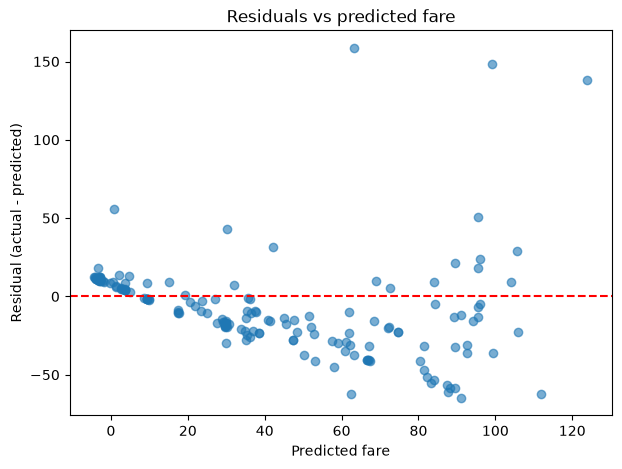

Correlation between predicted fare and |residual|: 0.546


In [11]:
reg_df = df.dropna(subset=["fare"]).copy()
reg_numeric = ["pclass", "age", "sibsp", "parch", "survived"]
reg_categorical = ["sex", "embarked"]
Xr = reg_df[reg_numeric + reg_categorical]
yr = reg_df["fare"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=RANDOM_STATE
)

reg_prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), reg_numeric),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), reg_categorical),
])

reg_pipe = Pipeline([("prep", reg_prep), ("model", LinearRegression())])
reg_pipe.fit(Xr_train, yr_train)

pred_r = reg_pipe.predict(Xr_test)
n = len(yr_test)
p = reg_pipe.named_steps["prep"].get_feature_names_out().shape[0]

mae = mean_absolute_error(yr_test, pred_r)
rmse = np.sqrt(mean_squared_error(yr_test, pred_r))
r2 = r2_score(yr_test, pred_r)
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

reg_results = {"MAE": mae, "RMSE": rmse, "R²": r2, "Adj. R²": adj_r2}
print({k: round(v, 4) for k, v in reg_results.items()})

# Residual plot
residuals = yr_test - pred_r
plt.figure(figsize=(7, 5))
plt.scatter(pred_r, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted fare"); plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs predicted fare")
plt.show()

print("Correlation between predicted fare and |residual|:",
      round(np.corrcoef(pred_r, np.abs(residuals))[0, 1], 3))

**Heteroscedasticity conclusion (confirm against YOUR plot):**
The residuals [fan out / widen] as the predicted fare increases instead of forming an even, random band around zero,
and the correlation between predicted fare and |residual| is [value]. This indicates **heteroscedasticity**
(non-constant error variance): the model is far less reliable for expensive fares than for cheap ones, and
`fare` is heavily right-skewed. A log transform of `fare` or a different model would be a sensible next step.
*(If your plot instead shows an even random band, write that it shows no clear heteroscedasticity.)*

## Task 14: Final model comparison table + recommendation

Classification metrics and regression metrics sit in two **separate metric groups**. They are on different scales
and are not directly comparable, so the other group is left as "n/a".

In [12]:
clf_part = clf_results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].copy()
clf_part.columns = pd.MultiIndex.from_product([["Classification metrics"], clf_part.columns])

reg_part = pd.DataFrame(reg_results, index=["Linear Regression (predict fare)"])[["MAE", "RMSE", "R²", "Adj. R²"]]
reg_part.columns = pd.MultiIndex.from_product([["Regression metrics"], reg_part.columns])

comparison_table = pd.concat([clf_part, reg_part]).round(3).fillna("n/a")
comparison_table

Classification metrics                   \
                                               Accuracy Precision Recall   
Logistic Regression                               0.804     0.793  0.667   
Decision Tree                                     0.793     0.864  0.551   
Random Forest                                     0.816       0.8  0.696   
Random Forest (tuned)                             0.799     0.789  0.652   
Linear Regression (predict fare)                    n/a       n/a    n/a   

                                                Regression metrics          \
                                     F1 ROC-AUC                MAE    RMSE   
Logistic Regression               0.724   0.844                n/a     n/a   
Decision Tree                     0.673   0.829                n/a     n/a   
Random Forest                     0.744    0.83                n/a     n/a   
Random Forest (tuned)             0.714    0.84                n/a     n/a   
Linear Regression (predict fare)    n/a     n/a             20.898  30.533   

                                                 
                                     R² Adj. R²  
Logistic Regression                 n/a     n/a  
Decision Tree                       n/a     n/a  
Random Forest                       n/a     n/a  
Random Forest (tuned)               n/a     n/a  
Linear Regression (predict fare)  0.398   0.362

In [13]:
# Best classifier by F1 (ties broken by ROC-AUC); reused below for the saved artifact
best_name = clf_results.sort_values(["F1", "ROC-AUC"], ascending=False).index[0]
b = clf_results.loc[best_name]

print("Draft recommendation (edit it in your own words):\n")
print(f"I would deploy the {best_name}. On the held-out test set it achieved "
      f"accuracy {b['Accuracy']:.3f}, precision {b['Precision']:.3f}, recall {b['Recall']:.3f}, "
      f"F1 {b['F1']:.3f} and ROC-AUC {b['ROC-AUC']:.3f}, the best F1 of the classifiers compared. "
      f"[Add 1-2 sentences: how it compares with the other models, why F1/recall matters for catching survivors, "
      f"and a limitation such as the small dataset.] The regression model is a separate side-task "
      f"(R² = {r2:.3f}) and is not comparable with the classifiers.")

Draft recommendation (edit it in your own words):

I would deploy the Random Forest. On the held-out test set it achieved accuracy 0.816, precision 0.800, recall 0.696, F1 0.744 and ROC-AUC 0.830, the best F1 of the classifiers compared. [Add 1-2 sentences: how it compares with the other models, why F1/recall matters for catching survivors, and a limitation such as the small dataset.] The regression model is a separate side-task (R² = 0.398) and is not comparable with the classifiers.


**Final written recommendation (3 to 5 sentences, paste your edited version here):**
I would deploy the **[model name]**. [Cite its accuracy, precision, recall, F1 and ROC-AUC from the table.]
[Explain why it beats the other two, referencing specific values.] [Mention one limitation.]

## Task 15: Save the COMPLETE fitted pipeline and prove it reloads

The saved object is the whole `Pipeline` (imputer + scaler + encoder + final estimator), not the bare model,
so it works end-to-end on raw, unpreprocessed data.

In [14]:
full_pipeline = fitted_all[best_name]
print("Saving pipeline for:", best_name)
print("Steps:", [name for name, _ in full_pipeline.steps])

joblib.dump(full_pipeline, "titanic_full_pipeline.joblib")
print("Saved -> titanic_full_pipeline.joblib")

Saving pipeline for: Random Forest
Steps: ['prep', 'clf']
Saved -> titanic_full_pipeline.joblib


In [15]:
# Reload and predict on RAW (unpreprocessed) data
loaded = joblib.load("titanic_full_pipeline.joblib")

raw_sample = X_test.head(5)                      # raw columns, raw values, including any NaNs
print("Raw input:")
print(raw_sample)
print("\nPredictions from reloaded pipeline:", loaded.predict(raw_sample))
print("Predictions from original pipeline:", full_pipeline.predict(raw_sample))

same = np.array_equal(loaded.predict(X_test), full_pipeline.predict(X_test))
print("\nReloaded pipeline matches the original on the whole test set:", same)

# A brand-new passenger with a missing age, straight from raw values
new_passenger = pd.DataFrame([{
    "pclass": 1, "sex": "female", "age": np.nan, "sibsp": 0, "parch": 0, "fare": 80.0, "embarked": "C"
}])
print("New passenger survival prediction:", loaded.predict(new_passenger)[0],
      "| probability:", round(loaded.predict_proba(new_passenger)[0, 1], 3))

Raw input:
     pclass     sex   age  sibsp  parch     fare embarked
565       3    male  24.0      2      0  24.1500        S
160       3    male  44.0      0      1  16.1000        S
553       3    male  22.0      0      0   7.2250        C
860       3    male  41.0      2      0  14.1083        S
241       3  female   NaN      1      0  15.5000        Q

Predictions from reloaded pipeline: [0 0 0 0 1]
Predictions from original pipeline: [0 0 0 0 1]

Reloaded pipeline matches the original on the whole test set: True
New passenger survival prediction: 1 | probability: 1.0
